In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [10]:
# df = pd.read_csv('logs/2025-07-24-09-58-47_inferences.csv')
# df = pd.read_csv('logs/2025-07-24-11-06-21_inferences.csv')
# df = pd.read_csv('logs/2025-07-24-11-27-59_inferences.csv')
# df = pd.read_csv('logs/2025-07-29-18-14-19_inferences.csv') # "fixed" model, tested on entire dataset
# df = pd.read_csv('logs/2025-07-29-18-18-04_inferences.csv') # "fixed" MSE model, tested only on test dataset
# df = pd.read_csv('logs/2025-07-29-18-47-08_inferences.csv') # "fixed" MAE model, tested only on test dataset
# df = pd.read_csv('logs/2025-07-30-09-45-43_inferences.csv') # "fixed" MRE model, tested only on test dataset
df = pd.read_csv('logs/2025-07-31-13-46-06_inferences.csv') # "fixed" MAE model, normalized targets, tested only on test dataset
df.describe()

,targets_100,preds_100,mae_100,mse_100,mre_100,targets_125,preds_125,mae_125,mse_125,mre_125,...,targets_3150,preds_3150,mae_3150,mse_3150,mre_3150,targets_4000,preds_4000,mae_4000,mse_4000,mre_4000
count,6565.000000,6565.000000,6.565000e+03,6.565000e+03,6565.000000,6565.000000,6565.000000,6565.000000,6.565000e+03,6565.000000,...,6565.000000,6565.000000,6565.000000,6.565000e+03,6565.000000,6565.000000,6565.000000,6565.000000,6.565000e+03,6565.000000
mean,0.732367,0.734825,1.156879e-02,3.012925e-04,1.605341,0.722869,0.726616,0.011975,3.240542e-04,1.684429,...,0.182828,0.173013,0.061301,6.317843e-03,41.528323,0.175155,0.158667,0.064366,7.174491e-03,46.914213
std,0.017651,0.002983,1.294145e-02,8.523639e-04,1.870236,0.017953,0.002971,0.013442,9.051082e-04,1.956974,...,0.081470,0.018298,0.050600,1.127144e-02,50.365723,0.085321,0.021667,0.055063,1.340492e-02,63.230080
min,0.616302,0.723464,1.788139e-07,3.197442e-14,0.000024,0.628035,0.711399,0.000005,2.273737e-11,0.000656,...,0.022318,0.083830,0.000007,5.617928e-11,0.004705,0.014970,0.046831,0.000051,2.649018e-09,0.036175
25%,0.726193,0.732887,3.603280e-03,1.298362e-05,0.490660,0.716382,0.724658,0.003692,1.362933e-05,0.509671,...,0.122349,0.161663,0.024129,5.821995e-04,13.953755,0.111021,0.144967,0.024488,5.996612e-04,15.887413
50%,0.735177,0.734912,7.833898e-03,6.136996e-05,1.065387,0.725506,0.726759,0.008085,6.537514e-05,1.109206,...,0.168806,0.174928,0.050013,2.501299e-03,28.957973,0.161021,0.160036,0.051786,2.681787e-03,31.763276
75%,0.742602,0.736845,1.436067e-02,2.062287e-04,1.943618,0.733195,0.728682,0.014870,2.211290e-04,2.049174,...,0.229705,0.186051,0.084573,7.152663e-03,48.659370,0.224311,0.173976,0.087545,7.664154e-03,52.358745
max,0.837977,0.747593,1.175442e-01,1.381665e-02,19.072505,0.845102,0.736422,0.122313,1.496049e-02,15.548436,...,0.584572,0.223049,0.414823,1.720785e-01,644.120434,0.593958,0.223700,0.461958,2.134054e-01,843.251537


In [11]:
frequencies = [100,125,160,200,250,315,400,500,630,800,1000,1250,1600,2000,2500,3150,4000]
frequencies_str = ['100','125','160','200','250','315','400','500','630','800','1000','1250','1600','2000','2500','3150','4000']
losses = ['mae', 'mse', 'mre']

## Comparing Predictions

In [12]:
pred = df[[f'preds_{freq}' for freq in frequencies]]
pred.describe()

,preds_100,preds_125,preds_160,preds_200,preds_250,preds_315,preds_400,preds_500,preds_630,preds_800,preds_1000,preds_1250,preds_1600,preds_2000,preds_2500,preds_3150,preds_4000
count,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000,6565.000000
mean,0.734825,0.726616,0.710687,0.692544,0.672117,0.654734,0.622827,0.526070,0.406432,0.369247,0.324364,0.289496,0.246308,0.192250,0.179367,0.173013,0.158667
std,0.002983,0.002971,0.003995,0.003673,0.005825,0.009580,0.014844,0.005870,0.005915,0.015505,0.031275,0.022865,0.016675,0.014030,0.016030,0.018298,0.021667
min,0.723464,0.711399,0.695336,0.676055,0.638882,0.608521,0.555035,0.501393,0.379130,0.309858,0.209635,0.180504,0.182159,0.115156,0.106720,0.083830,0.046831
25%,0.732887,0.724658,0.708068,0.690133,0.668625,0.648574,0.613265,0.522169,0.402515,0.359190,0.303857,0.276606,0.235471,0.184142,0.169212,0.161663,0.144967
50%,0.734912,0.726759,0.710604,0.692606,0.672427,0.655602,0.623324,0.526811,0.406427,0.369414,0.325011,0.291657,0.247551,0.193145,0.180544,0.174928,0.160036
75%,0.736845,0.728682,0.713215,0.695026,0.675932,0.661774,0.632749,0.530672,0.410461,0.379163,0.344819,0.305188,0.258858,0.201489,0.190380,0.186051,0.173976
max,0.747593,0.736422,0.729147,0.707697,0.691969,0.682599,0.675143,0.540508,0.422968,0.421749,0.429360,0.344642,0.286389,0.240783,0.232180,0.223049,0.223700


In [13]:
for freq in frequencies:
    print(f"Number of unique values for frequency {freq}: {pred[f'preds_{freq}'].nunique()}")

Number of unique values for frequency 100: 6445
Number of unique values for frequency 125: 6440
Number of unique values for frequency 160: 6476
Number of unique values for frequency 200: 6480
Number of unique values for frequency 250: 6501
Number of unique values for frequency 315: 6528
Number of unique values for frequency 400: 6540
Number of unique values for frequency 500: 6513
Number of unique values for frequency 630: 6533
Number of unique values for frequency 800: 6551
Number of unique values for frequency 1000: 6563
Number of unique values for frequency 1250: 6560
Number of unique values for frequency 1600: 6560
Number of unique values for frequency 2000: 6558
Number of unique values for frequency 2500: 6560
Number of unique values for frequency 3150: 6562
Number of unique values for frequency 4000: 6561


## Plotting Losses by Frequency

In [14]:
mean_mae_by_freq = np.zeros(len(frequencies))
mean_mse_by_freq = np.zeros(len(frequencies))
mean_mre_by_freq = np.zeros(len(frequencies))
for i, freq in enumerate(frequencies):
    mean_mae_by_freq[i] = df[f'mae_{freq}'].mean()
    mean_mse_by_freq[i] = df[f'mse_{freq}'].mean()
    mean_mre_by_freq[i] = df[f'mre_{freq}'].mean()

mean_mae = np.mean(mean_mae_by_freq)
mean_mse = np.mean(mean_mse_by_freq)
mean_mre = np.mean(mean_mre_by_freq)

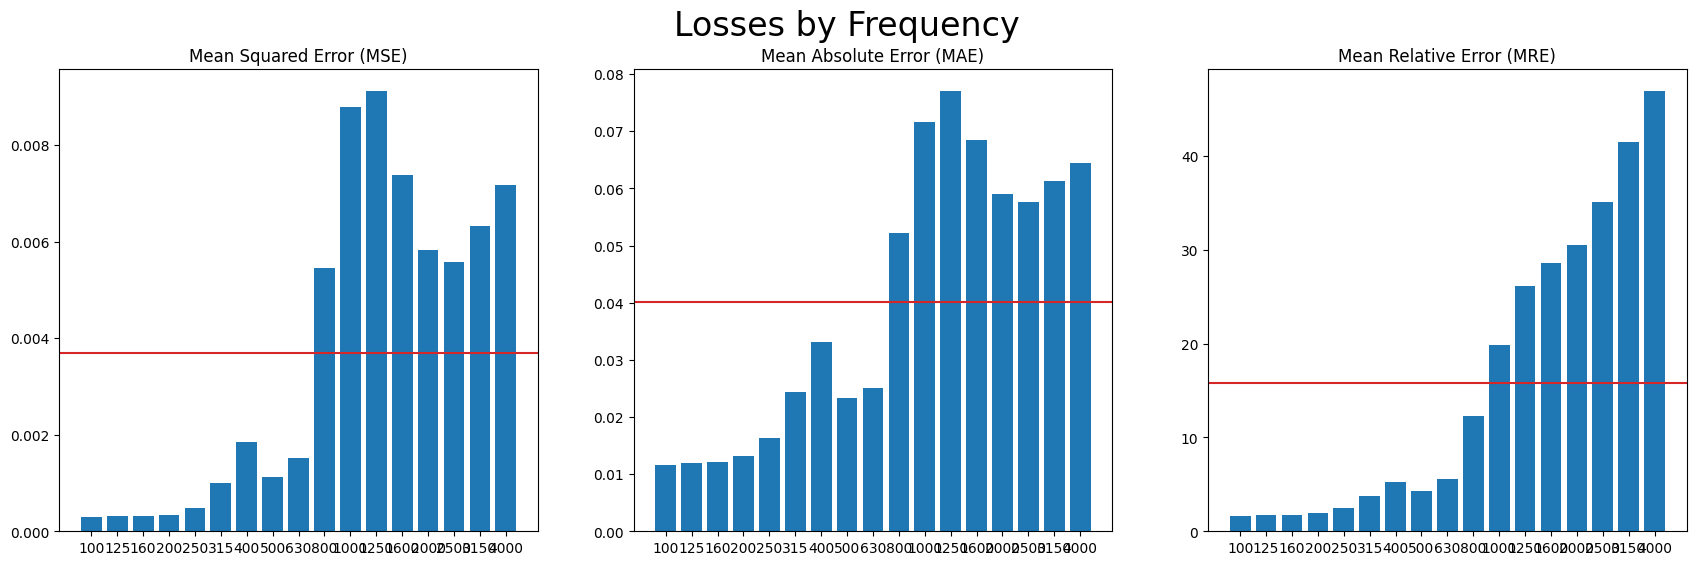

In [15]:
f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21,6))

f.suptitle('Losses by Frequency', fontsize=24)
ax1.bar(frequencies_str, mean_mse_by_freq)
ax1.set_title('Mean Squared Error (MSE)')
ax1.axhline(mean_mse, color='tab:red', label='Mean MSE')
ax2.bar(frequencies_str, mean_mae_by_freq)
ax2.set_title('Mean Absolute Error (MAE)')
ax2.axhline(mean_mae, color='tab:red', label='Mean MAE')
ax3.bar(frequencies_str, mean_mre_by_freq)
ax3.set_title('Mean Relative Error (MRE)')
ax3.axhline(mean_mre, color='tab:red', label='Mean MRE')

# plt.yticks([])

plt.show()

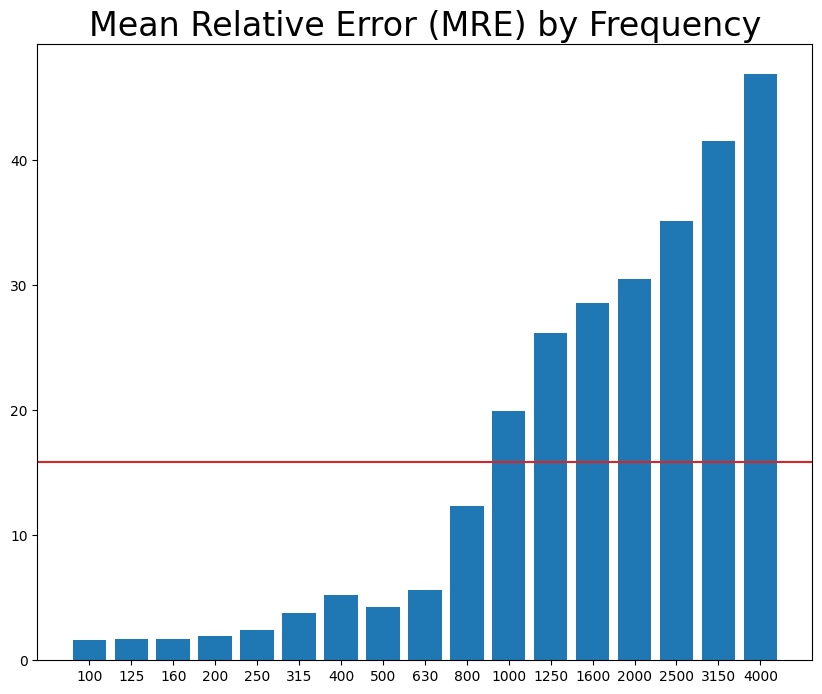

In [16]:
f, ax1 = plt.subplots(1, 1, figsize=(10,8))

ax1.bar(frequencies_str, mean_mre_by_freq)
ax1.set_title('Mean Relative Error (MRE) by Frequency', fontsize=24)
ax1.axhline(mean_mre, color='tab:red', label='Mean MRE')

# plt.yticks([])

plt.show()